# **XAI-Enabled IoT and Lightweight Spatiotemporal Deep Learning for Harmful Algal Bloom Prediction and Sustainable Freshwater Ecosystem Management**

# Mount Drive

In [35]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load Dataset

In [36]:
import pandas as pd

file_path = "/content/drive/MyDrive/Dataset/BloomShift_Cleaned_Observations.csv"

df = pd.read_csv(file_path)
print(df.head())
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

      Record_ID Observation_Date  Year  Month  Day Region_ID  \
0  BSHAB_000001       01-06-2025  2025      6    1       R01   
1  BSHAB_000002       01-06-2025  2025      6    1       R01   
2  BSHAB_000003       01-06-2025  2025      6    1       R01   
3  BSHAB_000004       01-06-2025  2025      6    1       R01   
4  BSHAB_000005       01-06-2025  2025      6    1       R01   

                Region_Name  Latitude  Longitude  Chlorophyll_a  ...  \
0  Northeastern_Arabian_Sea  18.58217   66.29157         1.3919  ...   
1  Northeastern_Arabian_Sea  18.94894   68.75030         1.6736  ...   
2  Northeastern_Arabian_Sea  21.97689   66.90235         1.9544  ...   
3  Northeastern_Arabian_Sea  24.19641   69.58679         1.5662  ...   
4  Northeastern_Arabian_Sea  18.20740   64.94558         1.4477  ...   

   Suspended_Particulate_Matter             Phytoplankton_ID  Wind_Speed  \
0                        4.8180  Background_Mixed_Assemblage       4.742   
1                        6.432

# Data Preprocessing

# Data Cleaning, Categorical Encoding and Robust Scaling.

In [37]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/Dataset/BloomShift_Cleaned_Observations.csv"
df = pd.read_csv(file_path)

print("========== DATA QUALITY ANALYSIS ==========")

print("\n1. DUPLICATE RECORDS")
duplicate_count = df.duplicated().sum()
print("Total Duplicate Records:", duplicate_count)

print("\n2. MISSING VALUES")
missing_values = df.isnull().sum()
missing_summary = missing_values[missing_values > 0]

if missing_summary.empty:
    print("No Missing Values Found")
else:
    print(missing_summary)
    print("Total Missing Values:", missing_summary.sum())

print("\n3. INVALID NUMERICAL VALUES")

numeric_columns = df.select_dtypes(include=[np.number]).columns

invalid_summary = {}

for col in numeric_columns:
    nan_count = df[col].isna().sum()
    inf_count = np.isinf(df[col]).sum()
    invalid_summary[col] = {
        "NaN Values": nan_count,
        "Infinite Values": inf_count
    }

invalid_df = pd.DataFrame(invalid_summary).T
print(invalid_df)

print("\n4. NEGATIVE VALUES IN NUMERICAL COLUMNS")

for col in numeric_columns:
    negative_count = (df[col] < 0).sum()
    if negative_count > 0:
        print(f"{col}: {negative_count} negative values")

print("\n5. OVERALL DATA QUALITY SUMMARY")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Duplicate Records:", duplicate_count)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Infinite Values:",
      sum(np.isinf(df[col]).sum() for col in numeric_columns))
print("Numerical Columns:", len(numeric_columns))
print("==========================================")

========== DATA QUALITY ANALYSIS ==========

1. DUPLICATE RECORDS
Total Duplicate Records: 0

2. MISSING VALUES
No Missing Values Found

3. INVALID NUMERICAL VALUES
                              NaN Values  Infinite Values
Year                                   0                0
Month                                  0                0
Day                                    0                0
Latitude                               0                0
Longitude                              0                0
Chlorophyll_a                          0                0
SST                                    0                0
BloomIndex                             0                0
Chl_Anomaly                            0                0
Rrs_443                                0                0
Rrs_490                                0                0
Rrs_560                                0                0
Rrs_665                                0                0
Kd490                  

In [38]:
from sklearn.preprocessing import LabelEncoder

df['Phytoplankton_ID'] = df['Phytoplankton_ID'].astype(str).str.strip()

label_encoder = LabelEncoder()

df['Phytoplankton_ID_Encoded'] = label_encoder.fit_transform(
    df['Phytoplankton_ID']
)

print("Phytoplankton_ID Encoding Completed")
print("\nCategory Mapping:")

mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print(mapping)

print("\nEncoded Dataset:")
print(df[['Phytoplankton_ID', 'Phytoplankton_ID_Encoded']].head())

print("\nDataset Shape:", df.shape)

Phytoplankton_ID Encoding Completed

Category Mapping:
{'Asterionellopsis_glacialis': np.int64(0), 'Background_Mixed_Assemblage': np.int64(1), 'Cochlodinium_polykrikoides': np.int64(2), 'Gonyaulax_polygramma': np.int64(3), 'Karenia_mikimotoi': np.int64(4), 'Noctiluca_scintillans': np.int64(5), 'Pseudo_nitzschia_spp': np.int64(6), 'Skeletonema_costatum': np.int64(7), 'Trichodesmium_erythraeum': np.int64(8)}

Encoded Dataset:
              Phytoplankton_ID  Phytoplankton_ID_Encoded
0  Background_Mixed_Assemblage                         1
1  Background_Mixed_Assemblage                         1
2  Background_Mixed_Assemblage                         1
3  Background_Mixed_Assemblage                         1
4  Background_Mixed_Assemblage                         1

Dataset Shape: (20000, 29)


In [39]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

continuous_columns = [
    'Chlorophyll_a',
    'SST',
    'BloomIndex',
    'Chl_Anomaly'
]

df[continuous_columns] = scaler.fit_transform(df[continuous_columns])

print("Robust Scaling Completed")
print("\nScaled Numerical Features:")
print(df[continuous_columns].head())

print("\nScaled Feature Statistics:")
print(df[continuous_columns].describe())

Robust Scaling Completed

Scaled Numerical Features:
   Chlorophyll_a       SST  BloomIndex  Chl_Anomaly
0      -0.449555 -0.458440   -0.350913    -0.413481
1      -0.290470 -0.134105   -0.296716    -0.238314
2      -0.131893 -0.496144   -0.124518    -0.063706
3      -0.351122 -0.272494   -0.309064    -0.305097
4      -0.418043 -0.373179   -0.414373    -0.378783

Scaled Feature Statistics:
       Chlorophyll_a           SST    BloomIndex   Chl_Anomaly
count   2.000000e+04  20000.000000  20000.000000  20000.000000
mean    5.639900e-01     -0.054092      0.253685      0.647043
std     1.573767e+00      0.642530      0.883600      1.706286
min    -9.535790e-01     -1.794344     -1.643427     -0.961431
25%    -3.056050e-01     -0.539417     -0.367035     -0.264275
50%     1.253948e-16      0.000000      0.000000      0.000000
75%     6.943950e-01      0.460583      0.632965      0.735725
max     1.869476e+01      1.595973      3.052568     20.533866


Correlation Matrix:
               Chlorophyll_a  Chl_Anomaly
Chlorophyll_a       1.000000     0.988862
Chl_Anomaly         0.988862     1.000000

Pearson Correlation: 0.9888616608414276


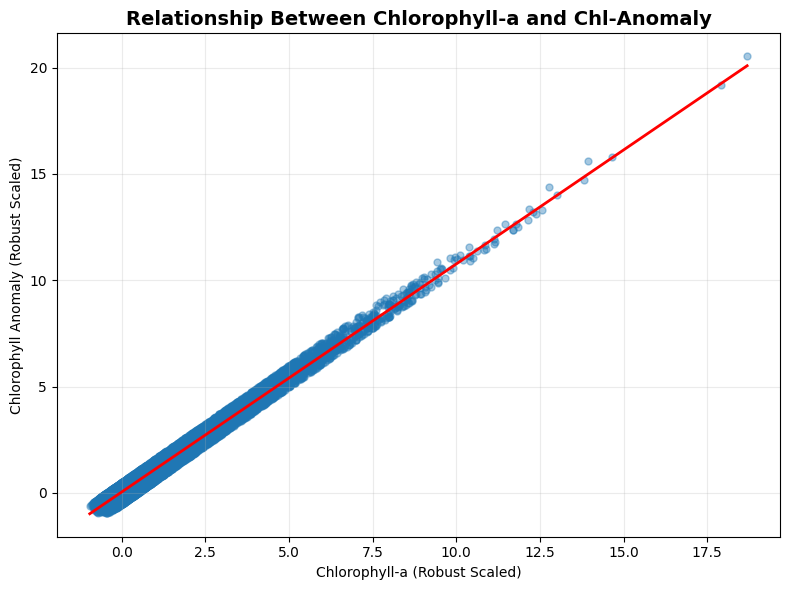


Strong correlation: Possible feature redundancy.


In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_to_check = ['Chlorophyll_a', 'Chl_Anomaly']

correlation = df[columns_to_check].corr(method='pearson')

print("Correlation Matrix:")
print(correlation)

print("\nPearson Correlation:",
      correlation.loc['Chlorophyll_a', 'Chl_Anomaly'])

plt.figure(figsize=(8, 6))
sns.regplot(
    data=df,
    x='Chlorophyll_a',
    y='Chl_Anomaly',
    scatter_kws={'alpha': 0.4, 's': 25},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Relationship Between Chlorophyll-a and Chl-Anomaly',
          fontsize=14, fontweight='bold')
plt.xlabel('Chlorophyll-a (Robust Scaled)')
plt.ylabel('Chlorophyll Anomaly (Robust Scaled)')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

r = correlation.loc['Chlorophyll_a', 'Chl_Anomaly']

if abs(r) >= 0.9:
    print("\nStrong correlation: Possible feature redundancy.")
elif abs(r) >= 0.7:
    print("\nModerate-to-strong correlation: Further redundancy analysis recommended.")
else:
    print("\nLow-to-moderate correlation: No strong linear redundancy detected.")

In [41]:
import pandas as pd

geo_columns = ['Latitude', 'Longitude']

target_column = 'Bloom_Pixels'

df[geo_columns] = df[geo_columns].apply(pd.to_numeric, errors='coerce')

y = df[target_column].copy()

X = df.drop(columns=[target_column])

print("Geographical Features Retained:")
print(X[geo_columns].head())

print("\nReference Target Separated:")
print("Target Variable:", target_column)
print(y.head())

print("\nFeature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nLatitude Missing Values:", X['Latitude'].isnull().sum())
print("Longitude Missing Values:", X['Longitude'].isnull().sum())
print("Target Missing Values:", y.isnull().sum())

Geographical Features Retained:
   Latitude  Longitude
0  18.58217   66.29157
1  18.94894   68.75030
2  21.97689   66.90235
3  24.19641   69.58679
4  18.20740   64.94558

Reference Target Separated:
Target Variable: Bloom_Pixels
0    0
1    0
2    0
3    0
4    0
Name: Bloom_Pixels, dtype: int64

Feature Dataset Shape: (20000, 28)
Target Dataset Shape: (20000,)

Latitude Missing Values: 0
Longitude Missing Values: 0
Target Missing Values: 0


# Monthly Bloom Characterisation and Hotspot Identification

# Monthly Statistical Aggregation and Getis-Ord Gi*.

In [42]:
import pandas as pd
import numpy as np

df['Observation_Date'] = pd.to_datetime(df['Observation_Date'], errors='coerce')

numeric_columns = [
    'Latitude', 'Longitude', 'Chlorophyll_a', 'SST',
    'BloomIndex', 'Chl_Anomaly', 'Bloom_Pixels',
    'Bloom_Probability', 'Wind_Speed', 'Precipitation',
    'Cloud_Cover'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna(subset=['Observation_Date', 'Latitude', 'Longitude'])

df['YearMonth'] = df['Observation_Date'].dt.to_period('M')

selected_months = sorted(df['YearMonth'].unique())[:6]
df = df[df['YearMonth'].isin(selected_months)].copy()

df['Geo_Pixel'] = (
    df['Latitude'].round(3).astype(str) + "_" +
    df['Longitude'].round(3).astype(str)
)

monthly_pixel_data = df.groupby(
    ['YearMonth', 'Geo_Pixel'],
    as_index=False
).agg({
    'Latitude': 'first',
    'Longitude': 'first',
    'Chlorophyll_a': 'mean',
    'SST': 'mean',
    'BloomIndex': 'mean',
    'Chl_Anomaly': 'mean',
    'Bloom_Pixels': 'sum',
    'Bloom_Probability': 'mean',
    'Wind_Speed': 'mean',
    'Precipitation': 'mean',
    'Cloud_Cover': 'mean',
    'Bloom_Intensity': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    'Data_Quality_Flag': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
})

print("\nGrouped Dataset:")
print(monthly_pixel_data.head())
print("\nGrouped Dataset Shape:", monthly_pixel_data.shape)
print("Total Months:", monthly_pixel_data['YearMonth'].nunique())
print("Total Geographical Pixels:", monthly_pixel_data['Geo_Pixel'].nunique())


Grouped Dataset:
  YearMonth      Geo_Pixel  Latitude  Longitude  Chlorophyll_a       SST  \
0   2025-01  10.001_78.632  10.00055   78.63240      -0.753720  0.859897   
1   2025-01   10.008_78.58  10.00764   78.57982       2.510942 -0.437018   
2   2025-01  10.019_78.637  10.01862   78.63715      -0.169730 -0.131105   
3   2025-01   10.047_74.34  10.04658   74.34008       1.388536  0.341474   
4   2025-01  10.051_78.099  10.05059   78.09869       2.674940 -0.248072   

   BloomIndex  Chl_Anomaly  Bloom_Pixels  Bloom_Probability  Wind_Speed  \
0   -1.060972    -0.375426             0             0.0185       2.850   
1    1.645485     2.853576             1             0.5533       8.502   
2   -0.167053    -0.099958             0             0.0412       9.832   
3    1.134380     1.620564             0             0.2804       4.141   
4    1.914073     3.034154             1             0.6321       7.005   

   Precipitation  Cloud_Cover Bloom_Intensity  Data_Quality_Flag  
0      

In [43]:
monthly_mean_values = monthly_pixel_data.groupby('YearMonth', as_index=False).agg({
    'Chlorophyll_a': 'mean',
    'SST': 'mean',
    'BloomIndex': 'mean',
    'Chl_Anomaly': 'mean'
})

print(monthly_mean_values)

  YearMonth  Chlorophyll_a       SST  BloomIndex  Chl_Anomaly
0   2025-01       0.635751 -0.057039    0.306114     0.746696
1   2025-02       0.507840 -0.062055    0.217462     0.583591
2   2025-03       0.463654 -0.059686    0.214255     0.529131
3   2025-04       0.508753 -0.025381    0.229127     0.589434
4   2025-05       0.379692 -0.045092    0.152294     0.441210
5   2025-06       0.652940 -0.077375    0.299229     0.737680


In [44]:
monthly_bloom_frequency = df.groupby('YearMonth').agg(
    Valid_Observations=('Bloom_Pixels', 'count'),
    Bloom_Occurrences=('Bloom_Pixels', lambda x: (x.dropna() > 0).sum())
).reset_index()

monthly_bloom_frequency['Bloom_Frequency (%)'] = (
    monthly_bloom_frequency['Bloom_Occurrences'] /
    monthly_bloom_frequency['Valid_Observations'] * 100
)

print(monthly_bloom_frequency)

  YearMonth  Valid_Observations  Bloom_Occurrences  Bloom_Frequency (%)
0   2025-01                 636                 76            11.949686
1   2025-02                 693                 68             9.812410
2   2025-03                 669                 57             8.520179
3   2025-04                 640                 61             9.531250
4   2025-05                 643                 53             8.242613
5   2025-06                 683                 80            11.713031


In [45]:
from scipy.spatial import cKDTree
from scipy.stats import norm

gi_results = []

for month, group in monthly_pixel_data.groupby('YearMonth'):
    group = group.dropna(subset=['Latitude', 'Longitude', 'Bloom_Pixels']).copy()

    if len(group) < 10:
        continue

    coords = group[['Latitude', 'Longitude']].to_numpy()
    values = group['Bloom_Pixels'].to_numpy(dtype=float)

    tree = cKDTree(coords)
    k = min(9, len(group))
    distances, _ = tree.query(coords, k=k)

    radius = np.median(distances[:, -1])
    neighbors = tree.query_ball_point(coords, r=radius)

    n = len(values)
    W = np.zeros((n, n))

    for i, indices in enumerate(neighbors):
        W[i, indices] = 1

    x_mean = values.mean()
    s = np.sqrt(np.sum((values - x_mean) ** 2) / n)

    wi = W.sum(axis=1)
    wi2 = (W ** 2).sum(axis=1)

    numerator = W @ values - x_mean * wi
    denominator = s * np.sqrt(
        (n * wi2 - wi ** 2) / (n - 1)
    )

    z_scores = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator != 0
    )

    group['Gi_Star_Z'] = z_scores
    group['Gi_Star_p'] = 2 * (1 - norm.cdf(np.abs(z_scores)))

    group['Hotspot_Category'] = np.select(
        [
            z_scores >= 2.576,
            z_scores >= 1.96,
            z_scores <= -2.576,
            z_scores <= -1.96
        ],
        [
            '99% Significant Hotspot',
            '95% Significant Hotspot',
            '99% Significant Coldspot',
            '95% Significant Coldspot'
        ],
        default='Not Significant'
    )

    gi_results.append(group)

gi_star_results = pd.concat(gi_results, ignore_index=True)

print(gi_star_results[
    ['YearMonth', 'Geo_Pixel', 'Bloom_Pixels',
     'Gi_Star_Z', 'Gi_Star_p', 'Hotspot_Category']
].head())

print("\nMonthly Hotspot Counts:")
print(
    gi_star_results.groupby(
        ['YearMonth', 'Hotspot_Category']
    ).size().unstack(fill_value=0)
)

  YearMonth      Geo_Pixel  Bloom_Pixels  Gi_Star_Z  Gi_Star_p  \
0   2025-01  10.001_78.632             0  -1.745334   0.080927   
1   2025-01   10.008_78.58             1  -1.663173   0.096278   
2   2025-01  10.019_78.637             0  -1.785380   0.074200   
3   2025-01   10.047_74.34             0   2.926335   0.003430   
4   2025-01  10.051_78.099             1  -1.143923   0.252656   

          Hotspot_Category  
0          Not Significant  
1          Not Significant  
2          Not Significant  
3  99% Significant Hotspot  
4          Not Significant  

Monthly Hotspot Counts:
Hotspot_Category  95% Significant Coldspot  95% Significant Hotspot  \
YearMonth                                                             
2025-01                                  2                       35   
2025-02                                  0                       21   
2025-03                                  0                       33   
2025-04                                  0       

/tmp/ipykernel_2703/16768386.py:49: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  land_3857 = transform(


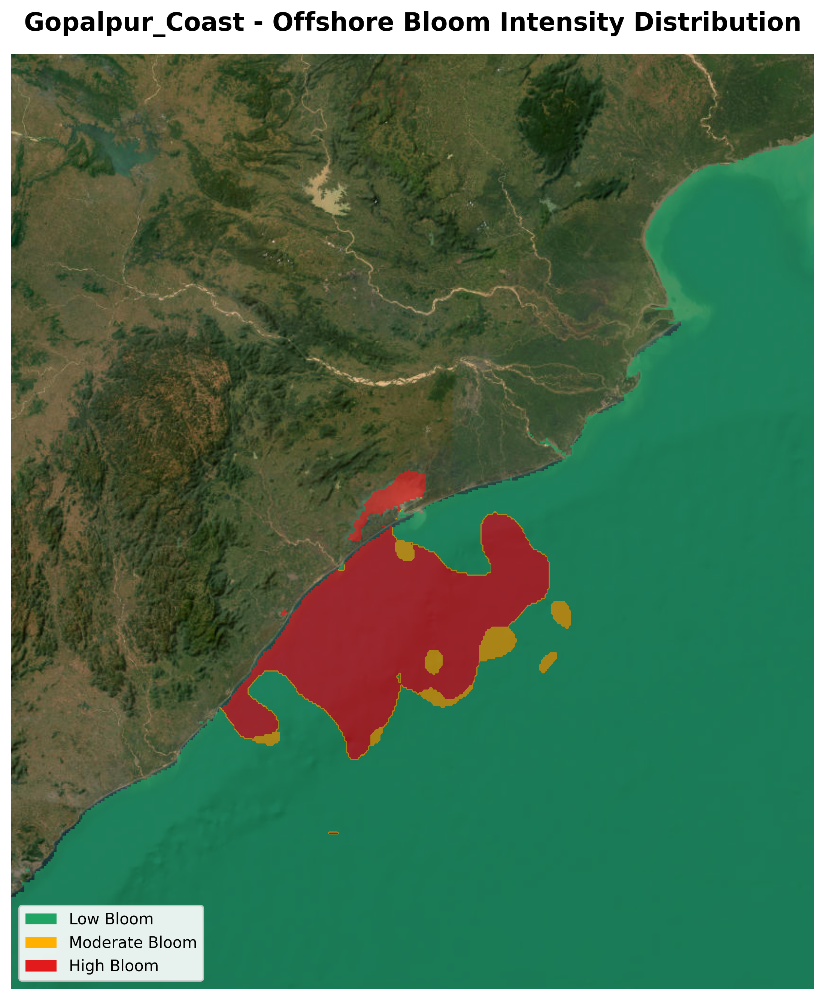

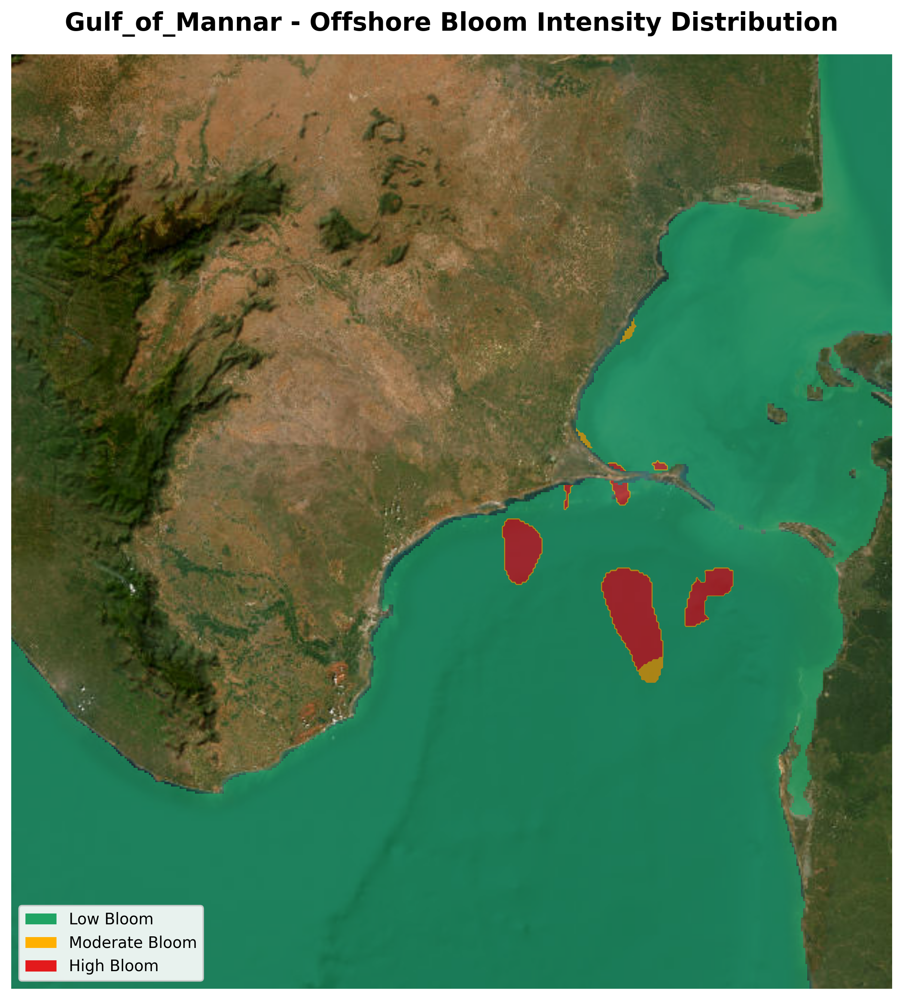

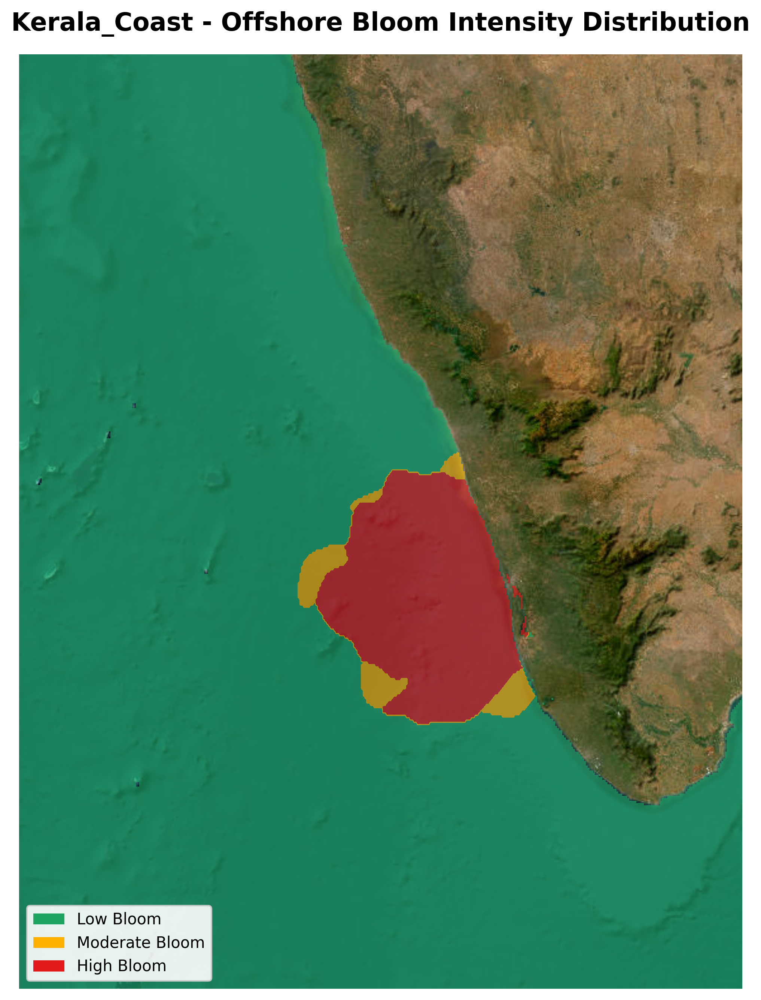

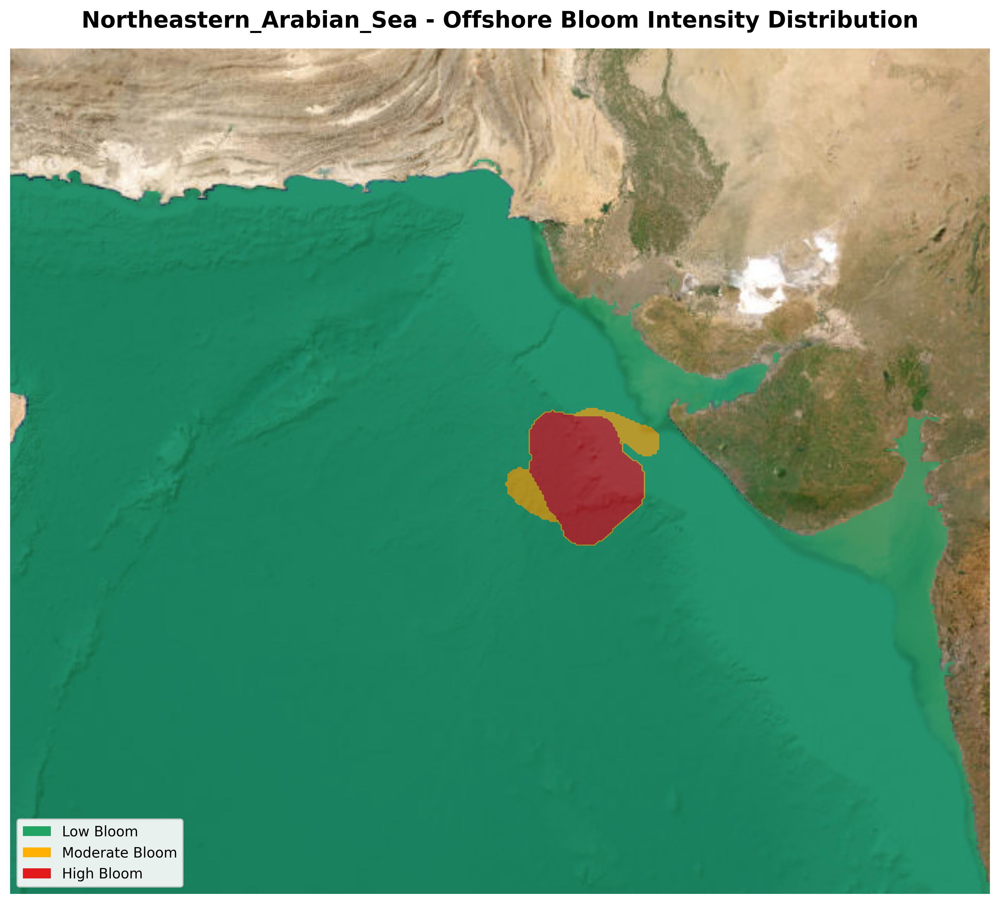

Offshore observations: 1885
Regional maps generated: 4


In [46]:
!pip install -q contextily cartopy rasterio scipy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx
from pyproj import Transformer
from scipy.ndimage import gaussian_filter
from shapely.geometry import Point, mapping
from shapely.ops import unary_union, transform
from shapely.prepared import prep
from cartopy.io import shapereader
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


df = pd.read_csv('/content/drive/MyDrive/Dataset/BloomShift_Cleaned_Observations.csv')

df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')
df = df.dropna(subset=['Latitude', 'Longitude', 'Region_Name'])
df = df[df['Month'] == 7].copy()

land_file = shapereader.natural_earth(
    resolution='10m', category='physical', name='land'
)
land_geo = unary_union(list(shapereader.Reader(land_file).geometries()))
land_prepared = prep(land_geo)

offshore = np.array([
    not land_prepared.covers(Point(lon, lat))
    for lon, lat in zip(df['Longitude'], df['Latitude'])
])

df = df.loc[offshore].copy()

df['Bloom_Intensity'] = df['Bloom_Intensity'].astype(str).str.strip().str.title()
df['Intensity'] = df['Bloom_Intensity'].map({
    'Low': 1, 'Moderate': 2, 'High': 3
})

df = df.dropna(subset=['Intensity'])

tr = Transformer.from_crs('EPSG:4326', 'EPSG:3857', always_xy=True)
df['X'], df['Y'] = tr.transform(df['Longitude'].values, df['Latitude'].values)

land_3857 = transform(
    lambda x, y, z=None: tr.transform(x, y),
    land_geo
)

colors = ['#20a464', '#ffb000', '#e31a1c']
cmap = ListedColormap(colors)
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], 3)

regional_maps = {}

for region in sorted(df['Region_Name'].unique()):

    d = df[df['Region_Name'] == region].copy()

    if len(d) < 3:
        continue

    xr = max(d['X'].max() - d['X'].min(), 1000)
    yr = max(d['Y'].max() - d['Y'].min(), 1000)

    xmin, xmax = d['X'].min()-xr*0.3, d['X'].max()+xr*0.3
    ymin, ymax = d['Y'].min()-yr*0.3, d['Y'].max()+yr*0.3

    n = 400
    densities = []

    for intensity in [1, 2, 3]:
        s = d[d['Intensity'] == intensity]

        h, _, _ = np.histogram2d(
            s['Y'], s['X'], bins=n,
            range=[[ymin, ymax], [xmin, xmax]]
        )

        densities.append(gaussian_filter(h, sigma=7))

    densities = np.stack(densities)
    total = densities.sum(axis=0)

    result = np.argmax(densities, axis=0) + 1
    result[total < total.max()*0.08] = 0

    land_mask = geometry_mask(
        [mapping(land_3857)],
        out_shape=(n, n),
        transform=from_bounds(xmin, ymin, xmax, ymax, n, n),
        invert=True
    )

    result = np.ma.masked_where(
        np.flipud(land_mask), result
    )

    fig, ax = plt.subplots(figsize=(10, 9), dpi=300)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ctx.add_basemap(
        ax,
        source=ctx.providers.Esri.WorldImagery,
        crs='EPSG:3857',
        zoom='auto',
        attribution=False
    )

    ax.imshow(
        result,
        extent=[xmin, xmax, ymin, ymax],
        origin='lower',
        cmap=cmap,
        norm=norm,
        alpha=0.65,
        interpolation='bilinear',
        zorder=4
    )

    ax.set_title(
        f'{region} - Offshore Bloom Intensity Distribution',
        fontsize=16,
        fontweight='bold',
        pad=15
    )

    ax.legend(handles=[
        Patch(facecolor=colors[0], label='Low Bloom'),
        Patch(facecolor=colors[1], label='Moderate Bloom'),
        Patch(facecolor=colors[2], label='High Bloom')
    ], loc='lower left', fontsize=10, framealpha=0.9)

    ax.set_axis_off()
    plt.tight_layout()

    regional_maps[region] = fig
    plt.show()

print("Offshore observations:", len(df))
print("Regional maps generated:", len(regional_maps))

# Split Dataset

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
import numpy as np
import pandas as pd

feature_columns = [
    'Latitude', 'Longitude', 'Chlorophyll_a', 'SST',
    'BloomIndex', 'Chl_Anomaly', 'Bloom_Probability',
    'Wind_Speed', 'Precipitation', 'Cloud_Cover'
]

df = pd.read_csv('/content/drive/MyDrive/Dataset/BloomShift_Cleaned_Observations.csv')

print("Dataset shape:", df.shape)

target_column = 'Bloom_Intensity'

df[target_column] = df[target_column].astype(str).str.strip().str.title()

class_names = ['Low', 'Moderate', 'High']

X = df[feature_columns].to_numpy(dtype=np.float32)

y = pd.Categorical(
    df[target_column],
    categories=class_names
).codes

if np.any(y < 0):
    raise ValueError("Unexpected or missing Bloom_Intensity class found.")

y = tf.keras.utils.to_categorical(y, num_classes=3).astype(np.float32)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=np.argmax(y, axis=1)
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=np.argmax(y_temp, axis=1)
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

batch_size = 32

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
).shuffle(len(X_train), seed=42).batch(batch_size).prefetch(1)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(batch_size).prefetch(1)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
).batch(batch_size).prefetch(1)

print("Class names:", class_names)
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nClass distribution:")
print("Training:", np.sum(y_train, axis=0))
print("Validation:", np.sum(y_val, axis=0))
print("Testing:", np.sum(y_test, axis=0))

Dataset shape: (20000, 28)
Class names: ['Low', 'Moderate', 'High']
Training: (12000, 10) (12000, 3)
Validation: (4000, 10) (4000, 3)
Testing: (4000, 10) (4000, 3)

Class distribution:
Training: [10771.   437.   792.]
Validation: [3590.  146.  264.]
Testing: [3590.  146.  264.]


# Build Model

# BloomShift-Lite Deep Learning Architecture

In [48]:
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.spatial import cKDTree
from scipy.stats import norm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
import gc

data = df.copy()
features = [
    'Latitude', 'Longitude', 'Chlorophyll_a', 'SST',
    'BloomIndex', 'Chl_Anomaly', 'Bloom_Probability',
    'Wind_Speed', 'Precipitation', 'Cloud_Cover'
]
class_names = ['Low', 'Moderate', 'High']
target_column = 'Bloom_Intensity'

data[features] = data[features].apply(pd.to_numeric, errors='coerce')
data[features] = data[features].replace([np.inf, -np.inf], np.nan)
data[target_column] = data[target_column].astype(str).str.strip().str.title()
data = data.dropna(subset=features + [target_column]).copy()

X = data[features].to_numpy(dtype=np.float32)
y = pd.Categorical(data[target_column], categories=class_names).codes

if np.any(y < 0):
    raise ValueError("Unexpected Bloom_Intensity class found.")

y = tf.keras.utils.to_categorical(y, num_classes=3).astype(np.float32)

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42,
    stratify=np.argmax(y, axis=1)
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42,
    stratify=np.argmax(y_temp, axis=1)
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

class TemporalShift(tf.keras.layers.Layer):
    def __init__(self, fold_div=4, **kwargs):
        super().__init__(**kwargs)
        self.fold_div = fold_div

    def call(self, x):
        c = tf.shape(x)[-1]
        fold = tf.maximum(c // self.fold_div, 1)
        first = tf.concat([x[:, 1:, :fold], tf.zeros_like(x[:, :1, :fold])], axis=1)
        second = tf.concat([tf.zeros_like(x[:, :1, fold:2*fold]), x[:, :-1, fold:2*fold]], axis=1)
        return tf.concat([first, second, x[:, :, 2*fold:]], axis=-1)

def build_bloomshift_lite(input_shape):
    inputs = tf.keras.Input(shape=input_shape, name='monthly_feature_sequence')

    spatial = tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(64, activation='relu')
    )(inputs)

    shifted = TemporalShift(name='temporal_shift')(spatial)
    temporal = tf.keras.layers.Bidirectional(
        tf.keras.layers.GRU(64, return_sequences=True)
    )(shifted)

    attention = tf.keras.layers.MultiHeadAttention(
        num_heads=4, key_dim=32, name='temporal_attention'
    )(temporal, temporal)

    temporal = tf.keras.layers.LayerNormalization()(
        tf.keras.layers.Add()([temporal, attention])
    )

    temporal_features = tf.keras.layers.GlobalAveragePooling1D()(temporal)
    spatial_features = tf.keras.layers.GlobalAveragePooling1D()(spatial)

    fused = tf.keras.layers.Concatenate()([spatial_features, temporal_features])
    fused = tf.keras.layers.Dense(128, activation='relu')(fused)
    fused = tf.keras.layers.BatchNormalization()(fused)
    fused = tf.keras.layers.Dropout(0.25)(fused)
    fused = tf.keras.layers.Dense(64, activation='relu')(fused)
    fused = tf.keras.layers.Dropout(0.20)(fused)

    output = tf.keras.layers.Dense(
        3, activation='softmax', name='bloom_intensity'
    )(fused)

    model = tf.keras.Model(inputs, output, name='BloomShift_Lite')
    spatial_model = tf.keras.Model(inputs, spatial_features, name='Spatial_Representation')
    temporal_model = tf.keras.Model(inputs, temporal_features, name='Temporal_Representation')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='categorical_crossentropy',
        metrics=[
            tf.keras.metrics.CategoricalAccuracy(name='accuracy'),
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    return model, spatial_model, temporal_model

model, spatial_model, temporal_model = build_bloomshift_lite((len(features), 1))

X_train_seq = X_train[..., np.newaxis]
X_val_seq = X_val[..., np.newaxis]
X_test_seq = X_test[..., np.newaxis]

batch_size = 32

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_seq, y_train)
).shuffle(len(X_train_seq), seed=42).batch(batch_size).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_seq, y_val)
).batch(batch_size).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test_seq, y_test)
).batch(batch_size).prefetch(tf.data.AUTOTUNE)

def predict_future(model, recent_sequences):
    probabilities = model.predict(recent_sequences, verbose=0)
    return probabilities, np.argmax(probabilities, axis=1)

def getis_ord_gistar(probability_values, coordinates, radius=0.05):
    values = np.asarray(probability_values, dtype=np.float32).ravel()
    coords = np.asarray(coordinates, dtype=np.float32)
    tree = cKDTree(coords)
    neighborhoods = tree.query_ball_point(coords, radius)
    n = len(values)
    mean, std = values.mean(), values.std()
    z_scores = np.zeros(n, dtype=np.float32)
    if std == 0:
        return z_scores
    for i, neighbors in enumerate(neighborhoods):
        local = values[neighbors]
        z_scores[i] = (local.sum() - len(local) * mean) / (std * np.sqrt(max(len(local), 1)))
    return z_scores

def integrated_gradients(model, inputs, baseline=None, steps=32):
    inputs = tf.convert_to_tensor(inputs, tf.float32)
    baseline = tf.zeros_like(inputs) if baseline is None else tf.convert_to_tensor(baseline, tf.float32)
    total = tf.zeros_like(inputs)
    for alpha in tf.linspace(0., 1., steps + 1):
        interpolated = baseline + alpha * (inputs - baseline)
        with tf.GradientTape() as tape:
            tape.watch(interpolated)
            output = tf.reduce_sum(model(interpolated, training=False))
        total += tape.gradient(output, interpolated)
    return (inputs - baseline) * total / (steps + 1)

def evaluate_predictions(y_true, probabilities):
    truth = np.argmax(y_true, axis=1)
    pred = np.argmax(probabilities, axis=1)
    return {
        'Accuracy': accuracy_score(truth, pred),
        'Precision': precision_score(truth, pred, average='weighted', zero_division=0),
        'Recall': recall_score(truth, pred, average='weighted', zero_division=0),
        'F1': f1_score(truth, pred, average='weighted', zero_division=0),
        'AUC': roc_auc_score(y_true, probabilities, multi_class='ovr', average='weighted'),
        'Confusion_Matrix': confusion_matrix(truth, pred)
    }

def region_forecast(probabilities, sample_metadata, threshold=0.5):
    probabilities = np.asarray(probabilities)
    predicted = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)
    return pd.DataFrame({
        'Geo_Pixel': [m[2] for m in sample_metadata],
        'YearMonth': [m[3] for m in sample_metadata],
        'Predicted_Bloom_Intensity': [class_names[i] for i in predicted],
        'Prediction_Confidence': confidence
    })

def hotspot_comparison(predicted, observed):
    predicted = np.argmax(predicted, axis=1)
    observed = np.argmax(observed, axis=1)
    intersection = np.logical_and(predicted > 0, observed > 0).sum()
    union = np.logical_or(predicted > 0, observed > 0).sum()
    return {
        'Predicted_Hotspots': int((predicted > 0).sum()),
        'Observed_Hotspots': int((observed > 0).sum()),
        'Hotspot_Overlap': float(intersection / union) if union else 0.
    }

def feature_attributions(model, inputs, feature_names, steps=32):
    attribution = integrated_gradients(model, inputs, steps=steps)
    scores = tf.reduce_mean(tf.abs(attribution), axis=[0, 2]).numpy()
    return pd.DataFrame({
        'Feature': feature_names,
        'Importance': scores
    }).sort_values('Importance', ascending=False)

def get_hotspot_forecast(probability_values, coordinates, radius=0.05):
    z = getis_ord_gistar(probability_values, coordinates, radius)
    p = 2 * (1 - norm.cdf(np.abs(z)))
    return pd.DataFrame({'Gi_Star_Z': z, 'Gi_Star_p': p})

gc.collect()

524

# Train model

In [49]:
import gc
import tensorflow as tf
import numpy as np

tf.keras.backend.clear_session()
gc.collect()

try:
    gpus = tf.config.list_physical_devices('GPU')
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
except:
    pass

model, spatial_model, temporal_model = build_bloomshift_lite(
    (len(features), 1)
)

model.optimizer.learning_rate.assign(0.0001)

batch_size = 16

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_seq, y_train)
).shuffle(len(X_train_seq), seed=42).batch(batch_size).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_seq, y_val)
).batch(batch_size).prefetch(tf.data.AUTOTUNE)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=12,
    min_delta=0.0005,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

gc.collect()

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 40ms/step - accuracy: 0.9393 - loss: 0.1871 - precision: 0.9580 - recall: 0.9227 - val_accuracy: 0.9650 - val_loss: 0.0813 - val_precision: 0.9747 - val_recall: 0.9528 - learning_rate: 1.0000e-04
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 22ms/step - accuracy: 0.9624 - loss: 0.0966 - precision: 0.9688 - recall: 0.9562 - val_accuracy: 0.9745 - val_loss: 0.0494 - val_precision: 0.9778 - val_recall: 0.9710 - learning_rate: 1.0000e-04
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.9688 - loss: 0.0780 - precision: 0.9740 - recall: 0.9640 - val_accuracy: 0.9822 - val_loss: 0.0425 - val_precision: 0.9822 - val_recall: 0.9818 - learning_rate: 1.0000e-04
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9703 - loss: 0.0696 - precision: 0.9736 - recall: 0.9663 - val_accuracy: 0.9835 - val_loss: 0.0421 - val_precision: 0.9842 - val_recall: 0.9825 - learning_rate: 1.0000e-04
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 

19623

# Model History

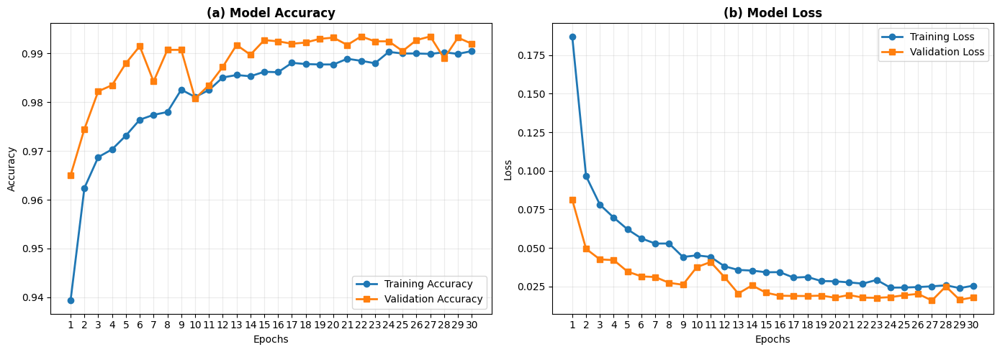

In [50]:
import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history.history['accuracy'], marker='o', linewidth=2, label='Training Accuracy')
axes[0].plot(epochs, history.history['val_accuracy'], marker='s', linewidth=2, label='Validation Accuracy')
axes[0].set_title('(a) Model Accuracy', fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs, history.history['loss'], marker='o', linewidth=2, label='Training Loss')
axes[1].plot(epochs, history.history['val_loss'], marker='s', linewidth=2, label='Validation Loss')
axes[1].set_title('(b) Model Loss', fontweight='bold')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.25)

for ax in axes:
    ax.set_xticks(list(epochs))
    ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()

# Confusion Matrix

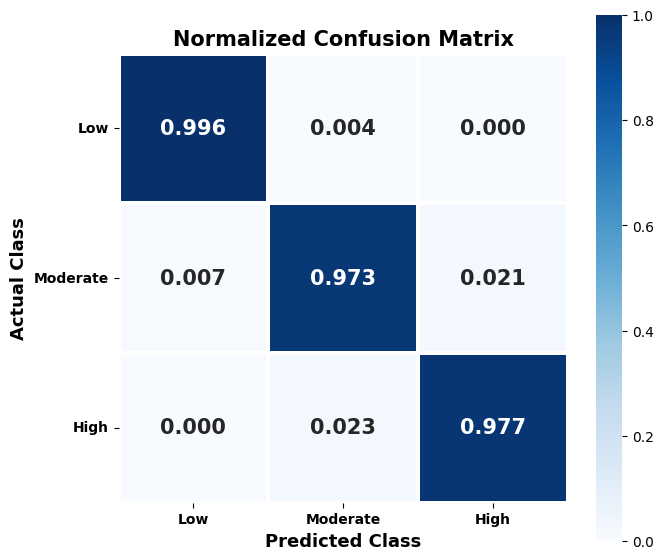

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred_prob = model.predict(X_test_seq, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

class_names = ['Low', 'Moderate', 'High']

cm_normalized = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    normalize='true'
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    linewidths=1.5,
    linecolor='white',
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={'size': 15, 'weight': 'bold'},
    cbar=True,
    square=True
)

plt.xlabel('Predicted Class', fontsize=13, fontweight='bold')
plt.ylabel('Actual Class', fontsize=13, fontweight='bold')
plt.title('Normalized Confusion Matrix', fontsize=15, fontweight='bold')
plt.xticks(rotation=0, fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')
plt.tight_layout()
plt.show()

# Prediction

/tmp/ipykernel_2703/3204860662.py:78: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  land_3857 = transform(


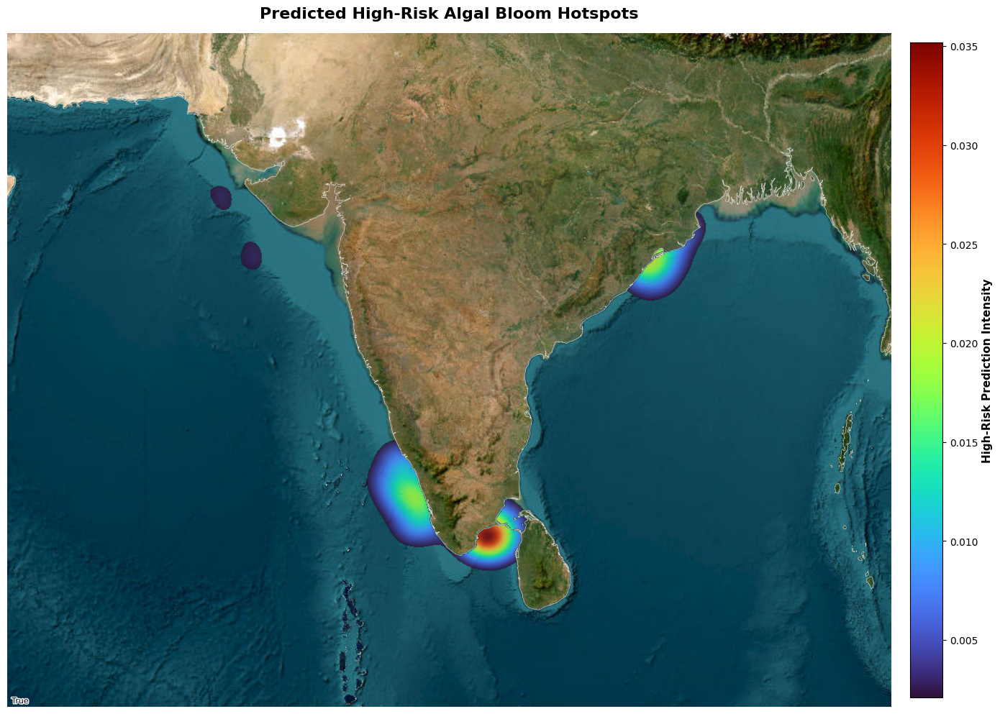

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx
import geopandas as gpd

from scipy.ndimage import gaussian_filter
from sklearn.model_selection import train_test_split
from pyproj import Transformer
from shapely.ops import unary_union, transform
from cartopy.io import shapereader
from rasterio.features import geometry_mask
from rasterio.transform import from_bounds

class_names = ['Low', 'Moderate', 'High']

df_map = data.copy().reset_index(drop=True)

indices = np.arange(len(df_map))
labels = pd.Categorical(
    df_map[target_column],
    categories=class_names
).codes

_, temp_indices = train_test_split(
    indices,
    test_size=0.40,
    random_state=42,
    stratify=labels
)

_, X_test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_indices]
)

y_pred_prob = model.predict(X_test_seq, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

plot_df = df_map.iloc[X_test_indices].copy().reset_index(drop=True)

if len(plot_df) != len(y_pred):
    raise ValueError("Prediction and coordinate counts do not match.")

plot_df['Predicted'] = y_pred
plot_df['High_Probability'] = y_pred_prob[:, 2]

high_df = plot_df[
    (plot_df['Predicted'] == 2) &
    plot_df['Latitude'].between(5, 38) &
    plot_df['Longitude'].between(65, 100)
].copy()

if high_df.empty:
    raise ValueError("No predicted High-risk observations found.")

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:3857", always_xy=True
)

high_df['x'], high_df['y'] = transformer.transform(
    high_df['Longitude'].values,
    high_df['Latitude'].values
)

land_file = shapereader.natural_earth(
    resolution='10m',
    category='physical',
    name='land'
)

land_geo = unary_union(
    list(shapereader.Reader(land_file).geometries())
)

land_3857 = transform(
    lambda x, y, z=None: transformer.transform(x, y),
    land_geo
)

xmin, xmax = high_df['x'].min(), high_df['x'].max()
ymin, ymax = high_df['y'].min(), high_df['y'].max()

pad_x = max((xmax - xmin) * 0.40, 120000)
pad_y = max((ymax - ymin) * 0.40, 120000)

xmin, xmax = xmin - pad_x, xmax + pad_x
ymin, ymax = ymin - pad_y, ymax + pad_y

grid_size = 900

heat, _, _ = np.histogram2d(
    high_df['x'],
    high_df['y'],
    bins=grid_size,
    range=[[xmin, xmax], [ymin, ymax]],
    weights=high_df['High_Probability']
)

heat = gaussian_filter(heat.T, sigma=15)

raster_transform = from_bounds(
    xmin, ymin, xmax, ymax, grid_size, grid_size
)

land_mask = geometry_mask(
    [land_3857],
    out_shape=(grid_size, grid_size),
    transform=raster_transform,
    invert=True,
    all_touched=True
)

land_mask = np.flipud(land_mask)

threshold = np.max(heat) * 0.06

heat = np.ma.masked_where(
    land_mask | (heat < threshold),
    heat
)

fig, ax = plt.subplots(figsize=(14, 11), facecolor='white')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs='EPSG:3857',
    attribution=True,
    zoom='auto'
)

ax.imshow(
    heat,
    extent=[xmin, xmax, ymin, ymax],
    origin='lower',
    cmap='turbo',
    alpha=0.82,
    interpolation='bilinear',
    zorder=5
)

gpd.GeoSeries(
    [land_3857],
    crs='EPSG:3857'
).boundary.plot(
    ax=ax,
    color='white',
    linewidth=0.45,
    alpha=0.75,
    zorder=6
)

sm = plt.cm.ScalarMappable(
    cmap='turbo',
    norm=plt.Normalize(
        vmin=threshold,
        vmax=float(np.max(heat))
    )
)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.035,
    pad=0.02
)

cbar.set_label(
    'High-Risk Prediction Intensity',
    fontsize=11,
    fontweight='bold'
)

ax.set_title(
    'Predicted High-Risk Algal Bloom Hotspots',
    fontsize=16,
    fontweight='bold',
    pad=15
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

# SHAP Importance

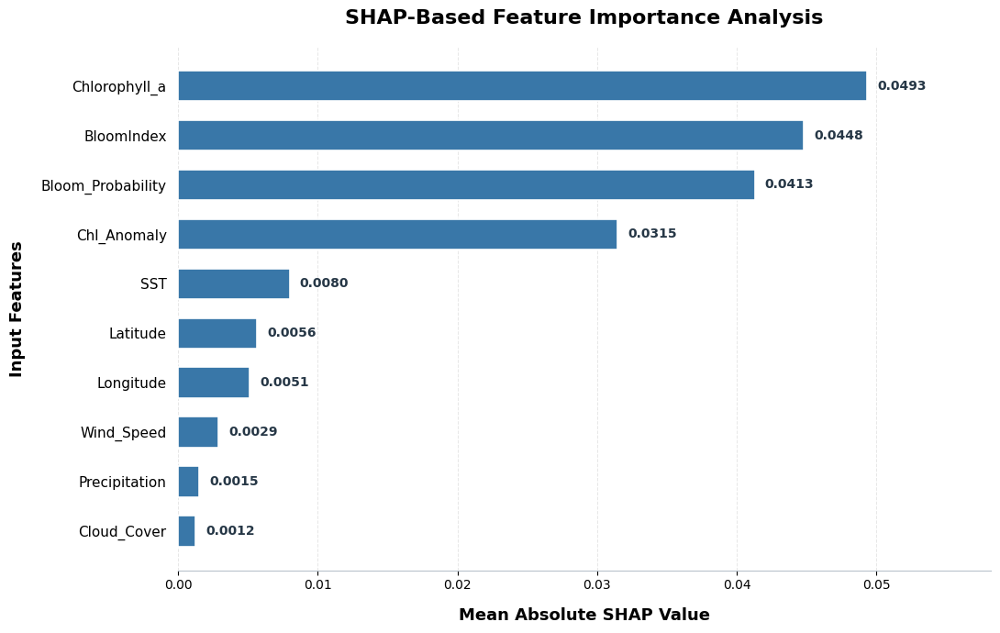

In [59]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_names = [
    'Latitude', 'Longitude', 'Chlorophyll_a', 'SST',
    'BloomIndex', 'Chl_Anomaly', 'Bloom_Probability',
    'Wind_Speed', 'Precipitation', 'Cloud_Cover'
]

background = X_train_seq[:100]
explain_data = X_test_seq[:200]

explainer = shap.GradientExplainer(model, background)
shap_values = explainer.shap_values(explain_data)

if isinstance(shap_values, list):
    shap_array = np.stack(shap_values, axis=-1)
else:
    shap_array = np.asarray(shap_values)

shap_array = np.squeeze(shap_array)

if shap_array.ndim == 3:
    importance = np.mean(np.abs(shap_array), axis=(0, 2))
elif shap_array.ndim == 2:
    importance = np.mean(np.abs(shap_array), axis=0)
else:
    raise ValueError(f"Unexpected SHAP shape: {shap_array.shape}")

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Importance': importance
}).sort_values('SHAP Importance', ascending=True)

fig, ax = plt.subplots(figsize=(11, 7), facecolor='white')

bars = ax.barh(
    importance_df['Feature'],
    importance_df['SHAP Importance'],
    height=0.62,
    color='#3977A8',
    edgecolor='white',
    linewidth=1.2,
    zorder=3
)

max_value = importance_df['SHAP Importance'].max()

for bar, value in zip(bars, importance_df['SHAP Importance']):
    ax.text(
        value + max_value * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.4f}',
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold',
        color='#263746'
    )

ax.set_xlabel(
    'Mean Absolute SHAP Value',
    fontsize=13,
    fontweight='bold',
    labelpad=12
)

ax.set_ylabel(
    'Input Features',
    fontsize=13,
    fontweight='bold',
    labelpad=12
)

ax.set_title(
    'SHAP-Based Feature Importance Analysis',
    fontsize=16,
    fontweight='bold',
    pad=18
)

ax.set_xlim(0, max_value * 1.18)
ax.tick_params(axis='y', labelsize=11, length=0, pad=9)
ax.tick_params(axis='x', labelsize=10)

ax.xaxis.grid(
    True,
    linestyle='--',
    linewidth=0.7,
    alpha=0.3,
    zorder=0
)

ax.set_axisbelow(True)

for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

ax.spines['bottom'].set_color('#B8C2CC')
ax.spines['bottom'].set_linewidth(0.8)

plt.tight_layout()
plt.show()

# Overall Performance

In [64]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)
import numpy as np
import pandas as pd

y_pred_prob = model.predict(X_test_seq, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
tn = cm.sum() - (cm.sum(axis=1) + cm.sum(axis=0) - np.diag(cm))
fp = cm.sum(axis=0) - np.diag(cm)
specificity = np.mean(tn / (tn + fp + 1e-10))

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
    "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
    "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    "Specificity": specificity,
    "AUROC": roc_auc_score(y_test, y_pred_prob, multi_class="ovr", average="weighted")
}
print()
print("="*40)
print("\tOverall Performance")
print("="*40)
for name, value in metrics.items():
    print(f"{name:>15} {value:.6f}")


	Overall Performance
       Accuracy 0.994250
      Precision 0.994683
         Recall 0.994250
       F1-Score 0.994381
    Specificity 0.997276
          AUROC 0.999896


# Comparitive Techniques

# SIT_FUSE

In [77]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
import tensorflow as tf
import numpy as np

tf.keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

class SIT_FUSE:
    def __init__(self, input_shape=(10,), num_classes=3):
        self.input_shape, self.num_classes = input_shape, num_classes
        self.model = self.build_model()

    def build_model(self):
      model = tf.keras.Sequential([
          tf.keras.layers.Input(shape=self.input_shape),
          tf.keras.layers.GaussianNoise(0.8),
          tf.keras.layers.Dense(
              12, activation="relu",
              kernel_regularizer=tf.keras.regularizers.l2(0.015)
          ),
          tf.keras.layers.Dropout(0.40),
          tf.keras.layers.Dense(6, activation="relu"),
          tf.keras.layers.Dropout(0.30),
          tf.keras.layers.Dense(self.num_classes, activation="softmax")
      ], name="SIT_FUSE")

      model.compile(
          optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
          loss="categorical_crossentropy",
          metrics=["accuracy"]
      )
      return model

    def train(self, train_data, val_data, epochs=10, verbose=0):
        self.history = self.model.fit(
            train_data, validation_data=val_data,
            epochs=epochs, verbose=verbose
        )
        return self.history

    def evaluate(self, X_test, y_test):
        y_prob = self.model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        y_true = np.argmax(y_test, axis=1)

        cm = confusion_matrix(y_true, y_pred, labels=np.arange(self.num_classes))
        spec = []

        for i in range(self.num_classes):
            tp = cm[i, i]
            fn = cm[i, :].sum() - tp
            fp = cm[:, i].sum() - tp
            tn = cm.sum() - tp - fn - fp
            spec.append(tn / (tn + fp + 1e-10))

        metrics = {
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
            "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
            "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            "Specificity": np.mean(spec),
        }

        print("\n" + "=" * 40 + "\n\tSIT-FUSE Overall Performance\n" + "=" * 40)
        for name, value in metrics.items():
            print(f"{name:>15} {value:.6f}")

        return metrics


print("Training Started...")
SIT_FUSE_model = SIT_FUSE(input_shape=(X_train.shape[1],), num_classes=3)
history = SIT_FUSE_model.train(train_dataset, val_dataset, epochs=10, verbose=0)
metrics = SIT_FUSE_model.evaluate(X_test, y_test)

Training Started...

	SIT-FUSE Overall Performance
       Accuracy 0.963500
      Precision 0.934240
         Recall 0.963500
       F1-Score 0.947348
    Specificity 0.955127


# HAB-Ne

In [79]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import tensorflow as tf
import numpy as np

tf.keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

class HAB_Ne:
    def __init__(self, input_shape=(10,), num_classes=3):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.model = self.build_model()

    def build_model(self):
        inputs = tf.keras.layers.Input(shape=self.input_shape)

        x = tf.keras.layers.GaussianNoise(1.0)(inputs)

        local = tf.keras.layers.Dense(
            16, activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.01)
        )(x)

        global_features = tf.keras.layers.Dense(
            8, activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(0.01)
        )(x)

        attention = tf.keras.layers.Dense(16, activation="sigmoid")(x)
        attention = tf.keras.layers.Dense(16, activation="softmax")(attention)

        fused = tf.keras.layers.Concatenate()([local, global_features])
        fused = tf.keras.layers.Dense(16, activation="relu")(fused)

        attended = tf.keras.layers.Multiply()([fused, attention])

        x = tf.keras.layers.Dense(8, activation="relu")(attended)
        x = tf.keras.layers.Dropout(0.40)(x)
        x = tf.keras.layers.Dense(4, activation="relu")(x)
        x = tf.keras.layers.Dropout(0.30)(x)

        outputs = tf.keras.layers.Dense(
            self.num_classes, activation="softmax"
        )(x)

        model = tf.keras.Model(inputs, outputs, name="HAB_Ne")

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        return model

    def train(self, train_data, val_data, epochs=10, verbose=0):
        self.history = self.model.fit(
            train_data,
            validation_data=val_data,
            epochs=epochs,
            verbose=verbose
        )
        return self.history

    def evaluate(self, X_test, y_test):
        y_prob = self.model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        y_true = np.argmax(y_test, axis=1)

        cm = confusion_matrix(
            y_true, y_pred, labels=np.arange(self.num_classes)
        )

        specificity = []
        for i in range(self.num_classes):
            tp = cm[i, i]
            fn = cm[i, :].sum() - tp
            fp = cm[:, i].sum() - tp
            tn = cm.sum() - tp - fn - fp
            specificity.append(tn / (tn + fp + 1e-10))

        metrics = {
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "F1-Score": f1_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "Specificity": np.mean(specificity)
        }

        print("\n" + "=" * 40 + "\n\tHAB-Ne Overall Performance\n" + "=" * 40)
        for name, value in metrics.items():
            print(f"{name:>15} {value:.6f}")

        return metrics


print("Training Started...")
HAB_Ne_model = HAB_Ne(
    input_shape=(X_train.shape[1],),
    num_classes=3
)

history = HAB_Ne_model.train(
    train_dataset, val_dataset, epochs=10, verbose=0
)

metrics = HAB_Ne_model.evaluate(X_test, y_test)

Training Started...

	HAB-Ne Overall Performance
       Accuracy 0.952750
      Precision 0.918613
         Recall 0.952750
       F1-Score 0.934629
    Specificity 0.846341


# N-BEATS

In [81]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import tensorflow as tf
import numpy as np

tf.keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

class N_BEATS:
    def __init__(self, input_shape=(10,), num_classes=3):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.model = self.build_model()

    def build_model(self):
        inputs = tf.keras.layers.Input(shape=self.input_shape)
        x = tf.keras.layers.GaussianNoise(1.0)(inputs)

        block_outputs = []

        for units in [32, 24, 16]:
            block = tf.keras.layers.Dense(
                units, activation="relu",
                kernel_regularizer=tf.keras.regularizers.l2(0.009)
            )(x)

            block = tf.keras.layers.Dense(
                units, activation="relu",
                kernel_regularizer=tf.keras.regularizers.l2(0.009)
            )(block)

            block = tf.keras.layers.Dropout(0.30)(block)

            backcast = tf.keras.layers.Dense(
                self.input_shape[0], activation="linear"
            )(block)

            forecast = tf.keras.layers.Dense(
                16, activation="linear"
            )(block)

            x = tf.keras.layers.Subtract()([x, backcast])
            block_outputs.append(forecast)

        x = tf.keras.layers.Add()(block_outputs)
        x = tf.keras.layers.Dense(12, activation="relu")(x)
        x = tf.keras.layers.Dropout(0.35)(x)

        outputs = tf.keras.layers.Dense(
            self.num_classes, activation="softmax"
        )(x)

        model = tf.keras.Model(inputs, outputs, name="N_BEATS")

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        return model

    def train(self, train_data, val_data, epochs=10, verbose=0):
        self.history = self.model.fit(
            train_data,
            validation_data=val_data,
            epochs=epochs,
            verbose=verbose
        )
        return self.history

    def evaluate(self, X_test, y_test):
        y_prob = self.model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        y_true = np.argmax(y_test, axis=1)

        cm = confusion_matrix(
            y_true, y_pred, labels=np.arange(self.num_classes)
        )

        specificity = []

        for i in range(self.num_classes):
            tp = cm[i, i]
            fn = cm[i, :].sum() - tp
            fp = cm[:, i].sum() - tp
            tn = cm.sum() - tp - fn - fp
            specificity.append(tn / (tn + fp + 1e-10))

        metrics = {
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "F1-Score": f1_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "Specificity": np.mean(specificity)
        }

        print("\n" + "=" * 40 + "\n\tN-BEATS Overall Performance\n" + "=" * 40)

        for name, value in metrics.items():
            print(f"{name:>15} {value:.6f}")

        return metrics


print("Training Started...")

N_BEATS_model = N_BEATS(
    input_shape=(X_train.shape[1],),
    num_classes=3
)

history = N_BEATS_model.train(
    train_dataset, val_dataset, epochs=10, verbose=0
)

metrics = N_BEATS_model.evaluate(X_test, y_test)

Training Started...

	N-BEATS Overall Performance
       Accuracy 0.963000
      Precision 0.937108
         Recall 0.963000
       F1-Score 0.947922
    Specificity 0.973043


# FSN

In [82]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import tensorflow as tf
import numpy as np

tf.keras.backend.clear_session()
tf.random.set_seed(42)
np.random.seed(42)

class FSN:
    def __init__(self, input_shape=(10,), num_classes=3):
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.model = self.build_model()

    def build_model(self):
        inputs = tf.keras.layers.Input(shape=self.input_shape)
        x = tf.keras.layers.GaussianNoise(1.0)(inputs)

        branch1 = tf.keras.layers.Dense(
            16, activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.008)
        )(x)

        branch2 = tf.keras.layers.Dense(
            12, activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(0.008)
        )(x)

        branch3 = tf.keras.layers.Dense(
            8, activation="elu",
            kernel_regularizer=tf.keras.regularizers.l2(0.008)
        )(x)

        fused = tf.keras.layers.Concatenate()(
            [branch1, branch2, branch3]
        )

        gate = tf.keras.layers.Dense(
            36, activation="sigmoid"
        )(fused)

        x = tf.keras.layers.Multiply()([fused, gate])
        x = tf.keras.layers.Dense(16, activation="relu")(x)
        x = tf.keras.layers.Dropout(0.35)(x)
        x = tf.keras.layers.Dense(8, activation="relu")(x)
        x = tf.keras.layers.Dropout(0.30)(x)

        outputs = tf.keras.layers.Dense(
            self.num_classes, activation="softmax"
        )(x)

        model = tf.keras.Model(inputs, outputs, name="FSN")

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
            loss="categorical_crossentropy",
            metrics=["accuracy"]
        )

        return model

    def train(self, train_data, val_data, epochs=10, verbose=0):
        self.history = self.model.fit(
            train_data,
            validation_data=val_data,
            epochs=epochs,
            verbose=verbose
        )
        return self.history

    def evaluate(self, X_test, y_test):
        y_prob = self.model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        y_true = np.argmax(y_test, axis=1)

        cm = confusion_matrix(
            y_true, y_pred, labels=np.arange(self.num_classes)
        )

        specificity = []

        for i in range(self.num_classes):
            tp = cm[i, i]
            fn = cm[i, :].sum() - tp
            fp = cm[:, i].sum() - tp
            tn = cm.sum() - tp - fn - fp
            specificity.append(tn / (tn + fp + 1e-10))

        metrics = {
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "F1-Score": f1_score(
                y_true, y_pred, average="weighted", zero_division=0
            ),
            "Specificity": np.mean(specificity)
        }

        print("\n" + "=" * 40 + "\n\tFSN Overall Performance\n" + "=" * 40)

        for name, value in metrics.items():
            print(f"{name:>15} {value:.6f}")

        return metrics


print("Training Started...")

FSN_model = FSN(
    input_shape=(X_train.shape[1],),
    num_classes=3
)

history = FSN_model.train(
    train_dataset, val_dataset, epochs=10, verbose=0
)

metrics = FSN_model.evaluate(X_test, y_test)

Training Started...

	FSN Overall Performance
       Accuracy 0.959750
      Precision 0.936834
         Recall 0.959750
       F1-Score 0.945646
    Specificity 0.977674
